<a href="https://colab.research.google.com/github/YeweonJung/workshop/blob/main/CDISC_SDTM%C2%B7ADaM_%EC%8B%A4%EC%8A%B5_(R).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CDISC SDTM · ADaM 실습 (R)

공개 예제 데이터인 **CDISC Pilot 01** 임상시험(경피 패치 xanomeline vs placebo, 알츠하이머 환자 306명)을 가지고 아래 흐름을 한 번에 따라간다.

1. 원자료(CRF/EMR 형태) → **SDTM** 매핑 (DM, AE)
2. SDTM 구조 점검 (키, 도메인, 통제용어)
3. SDTM → **ADaM** 생성 (ADSL, ADAE, ADVS) — `admiral` 패키지 사용
4. ADaM으로 분석 (인구학적 특성표, TEAE 요약, 혈압 변화량 ANCOVA)
5. 검증과 `.xpt` 내보내기

**실행 전:** 상단 메뉴 `런타임 → 런타임 유형 변경 → R` 로 바꾼 뒤 위에서부터 순서대로 실행한다.

## 0. 패키지 설치

`pharmaversesdtm`에 CDISC Pilot 01의 SDTM 데이터가 들어 있고, `admiral`은 ADaM 파생용 패키지다(Roche·GSK 등이 함께 만든 pharmaverse 프로젝트). Colab에서 처음 설치할 때 몇 분 걸린다.

In [1]:
pkgs <- c("admiral", "pharmaversesdtm", "dplyr", "tidyr", "lubridate", "stringr", "haven")
need <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(need) > 0) install.packages(need, Ncpus = 2)

suppressPackageStartupMessages({
  library(admiral)
  library(pharmaversesdtm)
  library(dplyr)
  library(tidyr)
  library(lubridate)
  library(stringr)
  library(haven)
})
options(width = 150, dplyr.summarise.inform = FALSE)
cat("admiral", as.character(packageVersion("admiral")),
    "/ pharmaversesdtm", as.character(packageVersion("pharmaversesdtm")), "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘admiraldev’




admiral 1.5.0 / pharmaversesdtm 1.5.0 


## 1. 원자료 만들기 (raw)

실제 업무에서는 EDC 추출본이나 병원 자료가 출발점이다. 여기서는 공개 SDTM을 일부러 **기관 원자료처럼 흐트러뜨린 뒤** 다시 SDTM으로 매핑해 본다. 그래야 마지막에 공식 SDTM과 대조해서 내 매핑이 맞았는지 확인할 수 있다.

원자료의 특징(일부러 넣은 것):
- 피험자 번호가 기관번호와 따로 있음 → `USUBJID`를 조합해야 함
- 성별이 1/2 코드, 인종이 소문자 자유 텍스트
- 날짜가 `YYYY.MM.DD` 문자열, 이상사례 시작일 일부는 연도나 연·월만 있음
- 중증도가 1/2/3 숫자 코드

In [2]:
data("dm", "ae", "ex", "vs", package = "pharmaversesdtm")
sdtm_dm_ref <- dm; sdtm_ae_ref <- ae   # 공식 SDTM (정답지)

to_dot_date <- function(x) str_replace_all(x, "-", ".")   # 2014-01-02 -> 2014.01.02

raw_demo <- sdtm_dm_ref %>%
  transmute(
    site      = SITEID,
    subj_no   = SUBJID,
    age       = AGE,
    sex_cd    = if_else(SEX == "M", 1L, 2L),
    race_txt  = tolower(RACE),
    ethnic_txt = tolower(ETHNIC),
    rand_arm  = ARM,
    death_yn  = if_else(DTHFL == "Y", "Y", "N", missing = "N"),
    death_dt  = to_dot_date(DTHDTC)
  )

raw_dosing <- ex %>%
  transmute(
    site = str_sub(USUBJID, 4, 6), subj_no = str_sub(USUBJID, 8),
    drug = EXTRT, dose_mg = EXDOSE,
    start_dt = to_dot_date(EXSTDTC), end_dt = to_dot_date(EXENDTC)
  )

raw_aelog <- sdtm_ae_ref %>%
  transmute(
    site = str_sub(USUBJID, 4, 6), subj_no = str_sub(USUBJID, 8),
    verbatim = AETERM,
    meddra_pt = AEDECOD, meddra_soc = AEBODSYS,   # 코딩은 이미 됐다고 가정
    onset  = to_dot_date(AESTDTC),
    resolved = to_dot_date(AEENDTC),
    severity_cd = recode(AESEV, MILD = 1L, MODERATE = 2L, SEVERE = 3L),
    serious = AESER,
    relation = AEREL
  )

cat("raw_demo:", dim(raw_demo), " raw_dosing:", dim(raw_dosing), " raw_aelog:", dim(raw_aelog), "\n")
head(raw_demo, 3); head(raw_aelog, 3)
table(nchar(raw_aelog$onset), useNA = "ifany")   # 4 = 연도만, 7 = 연.월만

raw_demo: 306 9  raw_dosing: 591 6  raw_aelog: 1191 10 


site,subj_no,age,sex_cd,race_txt,ethnic_txt,rand_arm,death_yn,death_dt
<chr>,<chr>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>
701,1015,63,2,white,hispanic or latino,Placebo,N,NA
701,1023,64,1,white,hispanic or latino,Placebo,N,NA
701,1028,71,1,white,not hispanic or latino,Xanomeline High Dose,N,NA


site,subj_no,verbatim,meddra_pt,meddra_soc,onset,resolved,severity_cd,serious,relation
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
701,1015,APPLICATION SITE ERYTHEMA,APPLICATION SITE ERYTHEMA,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,2014.01.03,NA,1,N,PROBABLE
701,1015,APPLICATION SITE PRURITUS,APPLICATION SITE PRURITUS,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,2014.01.03,NA,1,N,PROBABLE
701,1015,DIARRHOEA,DIARRHOEA,GASTROINTESTINAL DISORDERS,2014.01.09,2014.01.11,1,N,REMOTE



   4    7   10 
  11   15 1165 

## 2. 원자료 → SDTM

### 2-1. DM (Demographics): 피험자당 1행

핵심 규칙
- `STUDYID`, `DOMAIN`, `USUBJID`는 모든 도메인 공통 식별자. `USUBJID`는 시험 전체에서 유일해야 한다.
- 범주형 값은 **CDISC 통제용어(Controlled Terminology, CT)** 로 맞춘다 (예: SEX는 `M/F/U/UNDIFFERENTIATED`).
- 날짜는 **ISO 8601** 문자열(`YYYY-MM-DD`, 부분날짜는 `YYYY-MM` 또는 `YYYY`). 대치(imputation)는 SDTM에서 하지 않는다.
- `RFSTDTC`/`RFENDTC`(기준 시작·종료일)는 이 시험에선 첫/마지막 투약일로 정의.

In [3]:
studyid <- "CDISCPILOT01"
to_iso <- function(x) str_replace_all(x, "\\.", "-")

ref_dates <- raw_dosing %>%
  group_by(site, subj_no) %>%
  summarise(RFSTDTC = min(to_iso(start_dt)),
            RFENDTC = if (all(is.na(end_dt))) NA_character_ else max(to_iso(end_dt), na.rm = TRUE),
            .groups = "drop")

arm_ct <- tribble(
  ~rand_arm,                ~ARMCD,
  "Placebo",                "Pbo",
  "Xanomeline Low Dose",    "Xan_Lo",
  "Xanomeline High Dose",   "Xan_Hi",
  "Screen Failure",         "Scrnfail"
)

sdtm_dm <- raw_demo %>%
  left_join(ref_dates, by = c("site", "subj_no")) %>%
  left_join(arm_ct, by = "rand_arm") %>%
  transmute(
    STUDYID = studyid,
    DOMAIN  = "DM",
    USUBJID = paste("01", site, subj_no, sep = "-"),
    SUBJID  = subj_no,
    RFSTDTC, RFENDTC,
    DTHDTC  = to_iso(death_dt),
    DTHFL   = if_else(death_yn == "Y", "Y", NA_character_),
    SITEID  = site,
    AGE = age, AGEU = "YEARS",
    SEX     = c("M", "F")[sex_cd],
    RACE    = toupper(race_txt),
    ETHNIC  = toupper(ethnic_txt),
    ARMCD, ARM = rand_arm,
    COUNTRY = "USA"
  )

# 정답지와 대조
chk <- sdtm_dm %>%
  inner_join(sdtm_dm_ref, by = "USUBJID", suffix = c("", ".ref"))
sapply(c("SEX", "RACE", "ETHNIC", "AGE", "ARMCD", "RFSTDTC", "RFENDTC"), function(v)
  sum(!mapply(identical, chk[[v]], chk[[paste0(v, ".ref")]])))

SEX    RACE  ETHNIC     AGE   ARMCD RFSTDTC RFENDTC 
      0       0       0       0       0       0     133

실행해 보면 SEX·RACE·ETHNIC·AGE·ARMCD·RFSTDTC는 불일치 0이고 `RFENDTC`만 130여 건 다르다. 공식 DM의 `RFENDTC`는 "마지막 투약일"이 아니라 **시험 참여 종료일**(마지막 방문일)로 정의돼 있기 때문이다. 같은 변수라도 시험마다 정의가 다를 수 있어서, 실제 업무에선 **SDTM 매핑 명세서(mapping spec)** 에 변수별 출처와 규칙을 먼저 적고 코드를 짠다.

### 2-2. AE (Adverse Events): 이상사례 1건당 1행

- `AESEQ`: 피험자 안에서 레코드를 구분하는 일련번호
- `AESTDTC`: 부분날짜를 그대로 둔다 (`2014-03`처럼)
- `AESTDY`: 기준일(`RFSTDTC`) 대비 일수. **0일이 없다** (기준일이 1일, 그 전날이 -1일). 부분날짜면 계산하지 않는다.

In [4]:
sev_ct <- c("1" = "MILD", "2" = "MODERATE", "3" = "SEVERE")

study_day <- function(dtc, ref) {
  ok <- !is.na(dtc) & nchar(dtc) == 10 & !is.na(ref)
  d <- as.numeric(as.Date(dtc[ok]) - as.Date(ref[ok]))
  out <- rep(NA_real_, length(dtc)); out[ok] <- if_else(d >= 0, d + 1, d)
  out
}

sdtm_ae <- raw_aelog %>%
  mutate(USUBJID = paste("01", site, subj_no, sep = "-")) %>%
  left_join(select(sdtm_dm, USUBJID, RFSTDTC), by = "USUBJID") %>%
  transmute(
    STUDYID = studyid, DOMAIN = "AE", USUBJID,
    AETERM = verbatim, AEDECOD = meddra_pt, AEBODSYS = meddra_soc,
    AESEV = unname(sev_ct[as.character(severity_cd)]),
    AESER = serious, AEREL = relation,
    AESTDTC = to_iso(onset), AEENDTC = to_iso(resolved),
    AESTDY = study_day(AESTDTC, RFSTDTC),
    AEENDY = study_day(AEENDTC, RFSTDTC)
  ) %>%
  arrange(USUBJID, AESTDTC, AETERM) %>%
  group_by(USUBJID) %>% mutate(AESEQ = row_number()) %>% ungroup() %>%
  relocate(AESEQ, .after = USUBJID)

head(sdtm_ae, 5)
cat("AE 레코드 수 - 내 매핑:", nrow(sdtm_ae), " / 공식:", nrow(sdtm_ae_ref), "\n")
cat("AESTDY 일치:", sum(sdtm_ae$AESTDY %in% sdtm_ae_ref$AESTDY), "/", nrow(sdtm_ae), "(레코드 순서 무관 단순 비교)\n")

STUDYID,DOMAIN,USUBJID,AESEQ,AETERM,AEDECOD,AEBODSYS,AESEV,AESER,AEREL,AESTDTC,AEENDTC,AESTDY,AEENDY
<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
CDISCPILOT01,AE,01-701-1015,1,APPLICATION SITE ERYTHEMA,APPLICATION SITE ERYTHEMA,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,MILD,N,PROBABLE,2014-01-03,NA,2,NA
CDISCPILOT01,AE,01-701-1015,2,APPLICATION SITE PRURITUS,APPLICATION SITE PRURITUS,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,MILD,N,PROBABLE,2014-01-03,NA,2,NA
CDISCPILOT01,AE,01-701-1015,3,DIARRHOEA,DIARRHOEA,GASTROINTESTINAL DISORDERS,MILD,N,REMOTE,2014-01-09,2014-01-11,8,10
CDISCPILOT01,AE,01-701-1023,1,ERYTHEMA,ERYTHEMA,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,MILD,N,POSSIBLE,2012-08-07,2012-08-30,3,26
CDISCPILOT01,AE,01-701-1023,2,ERYTHEMA,ERYTHEMA,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,MODERATE,N,PROBABLE,2012-08-07,NA,3,NA


AE 레코드 수 - 내 매핑: 1191  / 공식: 1191 
AESTDY 일치: 1191 / 1191 (레코드 순서 무관 단순 비교)


## 3. SDTM 구조 점검

SDTM은 "분석용"이 아니라 **수집된 사실을 표준 모양으로 담는 그릇**이다. 도메인마다 한 행이 무엇을 뜻하는지(structure)와 키 변수가 정해져 있다.

| 도메인 | 한 행 = | 키 |
|---|---|---|
| DM | 피험자 1명 | STUDYID, USUBJID |
| AE | 이상사례 1건 | STUDYID, USUBJID, AESEQ |
| EX | 투약 구간 1개 | STUDYID, USUBJID, EXSEQ |
| VS | 측정값 1개 (검사×방문×시점) | STUDYID, USUBJID, VSTESTCD, VISITNUM, VSTPTNUM |

In [5]:
key_check <- function(df, keys, name) {
  dup <- df %>% count(across(all_of(keys))) %>% filter(n > 1) %>% nrow()
  cat(sprintf("%-4s 행 %6d | 키(%s) 중복 %d\n", name, nrow(df), paste(keys, collapse = ","), dup))
}
key_check(sdtm_dm, c("STUDYID", "USUBJID"), "DM")
key_check(sdtm_ae, c("STUDYID", "USUBJID", "AESEQ"), "AE")
key_check(ex, c("STUDYID", "USUBJID", "EXSEQ"), "EX")
key_check(vs, c("STUDYID", "USUBJID", "VSTESTCD", "VISITNUM", "VSTPTNUM"), "VS")

# AE에 있는데 DM에 없는 피험자 (있으면 안 됨)
anti_join(sdtm_ae, sdtm_dm, by = "USUBJID") %>% nrow()

# VS는 수직(long) 구조: 검사 항목이 열이 아니라 행으로 쌓인다
vs %>% count(VSTESTCD, VSPOS, VSTPT)

DM   행    306 | 키(STUDYID,USUBJID) 중복 0
AE   행   1191 | 키(STUDYID,USUBJID,AESEQ) 중복 0
EX   행    591 | 키(STUDYID,USUBJID,EXSEQ) 중복 0
VS   행  29643 | 키(STUDYID,USUBJID,VSTESTCD,VISITNUM,VSTPTNUM) 중복 0


[1] 0

VSTESTCD,VSPOS,VSTPT,n
<chr>,<chr>,<chr>,<int>
DIABP,STANDING,AFTER STANDING FOR 1 MINUTE,2735
DIABP,STANDING,AFTER STANDING FOR 3 MINUTES,2736
DIABP,SUPINE,AFTER LYING DOWN FOR 5 MINUTES,2736
HEIGHT,NA,NA,254
PULSE,STANDING,AFTER STANDING FOR 1 MINUTE,2734
PULSE,STANDING,AFTER STANDING FOR 3 MINUTES,2735
PULSE,SUPINE,AFTER LYING DOWN FOR 5 MINUTES,2735
SYSBP,STANDING,AFTER STANDING FOR 1 MINUTE,2735
SYSBP,STANDING,AFTER STANDING FOR 3 MINUTES,2736


## 4. SDTM → ADaM

ADaM은 **분석을 바로 돌릴 수 있게** 파생 변수를 붙인 데이터셋이다. 원칙은 "한 번의 프로시저로 분석 가능(analysis-ready)"과 "SDTM까지 추적 가능(traceability)".

- **ADSL** (Subject-Level): 피험자당 1행. 처리군, 투약 시작·종료일, 분석집단 플래그(SAFFL 등), 공변량.
- **BDS** (Basic Data Structure): 피험자×파라미터×시점당 1행. `PARAMCD`, `AVAL`, `BASE`, `CHG`, `ABLFL`, `AVISIT`.
- **OCCDS** (Occurrence Data Structure): 사건 1건당 1행. ADAE가 대표.

이후 단계에서는 공식 SDTM(`pharmaversesdtm`)을 입력으로 쓴다.

### 4-1. ADSL

In [6]:
ex_ext <- ex %>%
  derive_vars_dtm(dtc = EXSTDTC, new_vars_prefix = "EXST") %>%
  derive_vars_dtm(dtc = EXENDTC, new_vars_prefix = "EXEN", time_imputation = "last")

is_valid_dose <- function(dose, trt) dose > 0 | (dose == 0 & str_detect(trt, "PLACEBO"))

adsl <- dm %>%
  select(-DOMAIN) %>%
  mutate(TRT01P = ARM, TRT01A = ACTARM) %>%
  # 첫 투약 일시
  derive_vars_merged(
    dataset_add = ex_ext,
    filter_add  = is_valid_dose(EXDOSE, EXTRT) & !is.na(EXSTDTM),
    new_vars    = exprs(TRTSDTM = EXSTDTM),
    order       = exprs(EXSTDTM, EXSEQ),
    mode        = "first",
    by_vars     = exprs(STUDYID, USUBJID)
  ) %>%
  # 마지막 투약 일시
  derive_vars_merged(
    dataset_add = ex_ext,
    filter_add  = is_valid_dose(EXDOSE, EXTRT) & !is.na(EXENDTM),
    new_vars    = exprs(TRTEDTM = EXENDTM),
    order       = exprs(EXENDTM, EXSEQ),
    mode        = "last",
    by_vars     = exprs(STUDYID, USUBJID)
  ) %>%
  derive_vars_dtm_to_dt(source_vars = exprs(TRTSDTM, TRTEDTM)) %>%
  derive_var_trtdurd() %>%
  mutate(
    SAFFL  = if_else(!is.na(TRTSDT), "Y", "N"),          # 1회 이상 투약 = 안전성 분석군
    ITTFL  = if_else(ARMCD != "Scrnfail", "Y", "N"),      # 무작위배정 = ITT
    AGEGR1 = case_when(AGE < 65 ~ "<65", AGE <= 80 ~ "65-80", AGE > 80 ~ ">80"),
    AGEGR1N = case_when(AGEGR1 == "<65" ~ 1, AGEGR1 == "65-80" ~ 2, AGEGR1 == ">80" ~ 3),
    TRT01AN = case_when(TRT01A == "Placebo" ~ 0, TRT01A == "Xanomeline Low Dose" ~ 54,
                        TRT01A == "Xanomeline High Dose" ~ 81)
  )

adsl %>% select(USUBJID, TRT01A, TRTSDT, TRTEDT, TRTDURD, SAFFL, ITTFL, AGE, AGEGR1) %>% head()
adsl %>% count(TRT01A, SAFFL)

USUBJID,TRT01A,TRTSDT,TRTEDT,TRTDURD,SAFFL,ITTFL,AGE,AGEGR1
<chr>,<chr>,<date>,<date>,<dbl>,<chr>,<chr>,<dbl>,<chr>
01-701-1015,Placebo,2014-01-02,2014-07-02,182,Y,Y,63,<65
01-701-1023,Placebo,2012-08-05,2012-09-01,28,Y,Y,64,<65
01-701-1028,Xanomeline High Dose,2013-07-19,2014-01-14,180,Y,Y,71,65-80
01-701-1033,Xanomeline Low Dose,2014-03-18,2014-03-31,14,Y,Y,74,65-80
01-701-1034,Xanomeline High Dose,2014-07-01,2014-12-30,183,Y,Y,77,65-80
01-701-1047,Placebo,2013-02-12,2013-03-09,26,Y,Y,85,>80


TRT01A,SAFFL,n
<chr>,<chr>,<int>
Placebo,Y,86
Screen Failure,N,52
Xanomeline High Dose,Y,72
Xanomeline Low Dose,Y,96


### 4-2. ADAE (OCCDS)

- 부분날짜 대치: `AESTDTC = 2014-03` → `ASTDT = 2014-03-01` (`highest_imputation = "M"`, 첫날로 대치), 대치 수준은 `ASTDTF`에 남긴다.
- **TEAE(치료 후 발현 이상사례)**: 첫 투약일 이후 ~ 마지막 투약 후 30일 이내에 시작된 이상사례. 정의는 시험마다 SAP에 명시한다.

In [7]:
adae <- ae %>%
  derive_vars_merged(
    dataset_add = adsl,
    new_vars = exprs(TRTSDT, TRTEDT, TRT01A, TRT01AN, SAFFL, AGE, SEX),
    by_vars  = exprs(STUDYID, USUBJID)
  ) %>%
  derive_vars_dt(dtc = AESTDTC, new_vars_prefix = "AST",
                 highest_imputation = "M", date_imputation = "first") %>%
  derive_vars_dt(dtc = AEENDTC, new_vars_prefix = "AEN",
                 highest_imputation = "M", date_imputation = "last") %>%
  derive_vars_dy(reference_date = TRTSDT, source_vars = exprs(ASTDT, AENDT)) %>%
  mutate(
    TRTEMFL = if_else(!is.na(ASTDT) & !is.na(TRTSDT) &
                        ASTDT >= TRTSDT & ASTDT <= TRTEDT + days(30), "Y", NA_character_),
    ADURN = as.numeric(AENDT - ASTDT) + 1, ADURU = if_else(!is.na(ADURN), "DAYS", NA_character_),
    AESEVN = case_when(AESEV == "MILD" ~ 1, AESEV == "MODERATE" ~ 2, AESEV == "SEVERE" ~ 3)
  ) %>%
  # 피험자별 가장 심한 TEAE 1건 플래그 (최대 중증도 표에 사용)
  restrict_derivation(
    derivation = derive_var_extreme_flag,
    args = params(by_vars = exprs(USUBJID), order = exprs(desc(AESEVN), ASTDT, AESEQ),
                  new_var = AOCCIFL, mode = "first"),
    filter = TRTEMFL == "Y"
  )

adae %>% filter(!is.na(ASTDTF)) %>% select(USUBJID, AESTDTC, ASTDT, ASTDTF, ASTDY, TRTEMFL) %>% head()
adae %>% count(TRTEMFL)

USUBJID,AESTDTC,ASTDT,ASTDTF,ASTDY,TRTEMFL
<chr>,<chr>,<date>,<chr>,<dbl>,<chr>
01-701-1239,2014-03,2014-03-01,D,50,Y
01-701-1239,2014-04,2014-04-01,D,81,Y
01-716-1418,2013-07,2013-07-01,D,58,Y
01-716-1418,2013-07,2013-07-01,D,58,Y
01-716-1418,2013-07,2013-07-01,D,58,Y
01-716-1418,2013-07,2013-07-01,D,58,Y


TRTEMFL,n
<chr>,<int>
Y,1122
NA,69


### 4-3. ADVS (BDS)

- 혈압·맥박은 한 방문에 자세별 3회 측정 → 여기서는 **누운 자세 5분 후(SUPINE)** 값만 분석값으로 사용.
- 기저치(`ABLFL`): 첫 투약일 이전(포함) 측정값 중 **마지막** 값.
- `BASE`, `CHG = AVAL - BASE`, `PCHG`.

In [8]:
param_lookup <- tribble(
  ~VSTESTCD, ~PARAMCD, ~PARAM,                                  ~PARAMN,
  "SYSBP",   "SYSBP",  "Systolic Blood Pressure (mmHg)",        1,
  "DIABP",   "DIABP",  "Diastolic Blood Pressure (mmHg)",       2,
  "PULSE",   "PULSE",  "Pulse Rate (beats/min)",                3,
  "WEIGHT",  "WEIGHT", "Weight (kg)",                           4
)

advs <- vs %>%
  filter(VSTESTCD %in% param_lookup$VSTESTCD,
         is.na(VSPOS) | VSPOS == "SUPINE") %>%
  derive_vars_merged(dataset_add = adsl,
                     new_vars = exprs(TRTSDT, TRTEDT, TRT01A, TRT01AN, SAFFL),
                     by_vars = exprs(STUDYID, USUBJID)) %>%
  derive_vars_merged_lookup(dataset_add = param_lookup, by_vars = exprs(VSTESTCD),
                            new_vars = exprs(PARAMCD, PARAM, PARAMN)) %>%
  derive_vars_dt(dtc = VSDTC, new_vars_prefix = "A") %>%
  derive_vars_dy(reference_date = TRTSDT, source_vars = exprs(ADT)) %>%
  mutate(
    AVAL = VSSTRESN,
    AVISIT = case_when(
      str_detect(VISIT, "SCREEN|UNSCHED|RETRIEVAL|AMBUL") ~ NA_character_,
      VISIT == "BASELINE" ~ "Baseline",
      TRUE ~ str_to_title(VISIT)
    ),
    AVISITN = if_else(AVISIT == "Baseline", 0, as.numeric(str_extract(AVISIT, "\\d+")))
  ) %>%
  restrict_derivation(
    derivation = derive_var_extreme_flag,
    args = params(by_vars = exprs(STUDYID, USUBJID, PARAMCD),
                  order = exprs(ADT, VISITNUM, VSSEQ), new_var = ABLFL, mode = "last"),
    filter = !is.na(AVAL) & !is.na(ADT) & ADT <= TRTSDT
  ) %>%
  mutate(AVISIT = if_else(ABLFL %in% "Y", "Baseline", AVISIT),
         AVISITN = if_else(ABLFL %in% "Y", 0, AVISITN)) %>%
  derive_var_base(by_vars = exprs(STUDYID, USUBJID, PARAMCD),
                  source_var = AVAL, new_var = BASE) %>%
  derive_var_chg() %>%
  derive_var_pchg() %>%
  mutate(across(c(CHG, PCHG), ~ if_else(ADT > TRTSDT, .x, NA_real_)))  # 변화량은 투약 후 측정값에만

advs %>% filter(PARAMCD == "SYSBP", USUBJID == "01-701-1015") %>%
  select(USUBJID, PARAMCD, VISIT, AVISIT, ADT, ADY, AVAL, ABLFL, BASE, CHG) %>% print(n = 15)

All `VSTESTCD` are mapped.


# A tibble: 14 × 10
   USUBJID     PARAMCD VISIT               AVISIT   ADT          ADY  AVAL ABLFL  BASE   CHG
   <chr>       <chr>   <chr>               <chr>    <date>     <dbl> <dbl> <chr> <dbl> <dbl>
 1 01-701-1015 SYSBP   SCREENING 1         NA       2013-12-26    -7   131 NA      130    NA
 2 01-701-1015 SYSBP   SCREENING 2         NA       2013-12-31    -2   138 NA      130    NA
 3 01-701-1015 SYSBP   BASELINE            Baseline 2014-01-02     1   130 Y       130    NA
 4 01-701-1015 SYSBP   AMBUL ECG PLACEMENT NA       2014-01-14    13   137 NA      130     7
 5 01-701-1015 SYSBP   WEEK 2              Week 2   2014-01-16    15   114 NA      130   -16
 6 01-701-1015 SYSBP   WEEK 4              Week 4   2014-01-30    29   138 NA      130     8
 7 01-701-1015 SYSBP   AMBUL ECG REMOVAL   NA       2014-02-01    31   138 NA      130     8
 8 01-701-1015 SYSBP   WEEK 6              Week 6   2014-02-12    42   148 NA      130    18
 9 01-701-1015 SYSBP   WEEK 8              Week 8 

## 5. ADaM으로 분석

ADaM이 잘 만들어졌으면 분석 코드는 "필터 + 집계" 수준으로 짧아진다. 분석집단은 안전성 분석군(`SAFFL == "Y"`).

### 5-1. 인구학적 특성표 (Table 14.1.x 형태)

In [9]:
saf <- adsl %>% filter(SAFFL == "Y")
arm_lv <- c("Placebo", "Xanomeline Low Dose", "Xanomeline High Dose")
saf <- saf %>% mutate(TRT01A = factor(TRT01A, levels = arm_lv))
bign <- saf %>% count(TRT01A, name = "N")

fmt_cont <- function(df, var, label) {
  df %>% group_by(TRT01A) %>%
    summarise(val = sprintf("%.1f (%.1f)", mean({{ var }}, na.rm = TRUE), sd({{ var }}, na.rm = TRUE))) %>%
    mutate(item = label, level = "Mean (SD)")
}
fmt_cat <- function(df, var, label) {
  df %>% count(TRT01A, level = {{ var }}) %>% mutate(level = as.character(level)) %>%
    left_join(bign, by = "TRT01A") %>%
    mutate(val = sprintf("%d (%.1f%%)", n, 100 * n / N), item = label) %>% select(-n, -N)
}

table1 <- bind_rows(
  fmt_cont(saf, AGE, "Age (years)"),
  fmt_cat(mutate(saf, AGEGR1 = factor(AGEGR1, levels = c("<65", "65-80", ">80"))), AGEGR1, "Age group"),
  fmt_cat(saf, SEX, "Sex"),
  fmt_cat(saf, RACE, "Race")
) %>%
  pivot_wider(names_from = TRT01A, values_from = val, values_fill = "0") %>%
  select(item, level, all_of(arm_lv))
names(table1)[3:5] <- paste0(arm_lv, "\n(N=", bign$N, ")")
as.data.frame(table1)

item,level,Placebo (N=86),Xanomeline Low Dose (N=96),Xanomeline High Dose (N=72)
<chr>,<chr>,<chr>,<chr>,<chr>
Age (years),Mean (SD),75.2 (8.6),76.0 (8.1),73.8 (7.9)
Age group,<65,14 (16.3%),8 (8.3%),11 (15.3%)
Age group,65-80,42 (48.8%),53 (55.2%),49 (68.1%)
Age group,>80,30 (34.9%),35 (36.5%),12 (16.7%)
Sex,F,53 (61.6%),55 (57.3%),35 (48.6%)
Sex,M,33 (38.4%),41 (42.7%),37 (51.4%)
Race,BLACK OR AFRICAN AMERICAN,8 (9.3%),6 (6.2%),9 (12.5%)
Race,WHITE,78 (90.7%),90 (93.8%),62 (86.1%)
Race,AMERICAN INDIAN OR ALASKA NATIVE,0,0,1 (1.4%)


### 5-2. TEAE 요약 (SOC / PT별 피험자 수)

이상사례 표는 **건수가 아니라 피험자 수**로 센다(한 사람이 같은 PT를 여러 번 겪어도 1명).

In [10]:
teae <- adae %>% filter(SAFFL == "Y", TRTEMFL == "Y") %>%
  mutate(TRT01A = factor(TRT01A, levels = arm_lv))

any_teae <- teae %>% distinct(TRT01A, USUBJID) %>% count(TRT01A) %>%
  left_join(bign, by = "TRT01A") %>% mutate(pct = round(100 * n / N, 1))
cat("TEAE가 1건 이상인 피험자\n"); print(any_teae)

pt_tab <- teae %>% distinct(TRT01A, AEBODSYS, AEDECOD, USUBJID) %>%
  count(TRT01A, AEBODSYS, AEDECOD) %>%
  left_join(bign, by = "TRT01A") %>%
  mutate(val = sprintf("%d (%.1f)", n, 100 * n / N)) %>%
  select(-N) %>%
  pivot_wider(names_from = TRT01A, values_from = c(n, val), values_fill = list(n = 0, val = "0")) %>%
  mutate(total = rowSums(across(starts_with("n_")))) %>%
  arrange(desc(total)) %>%
  select(AEBODSYS, AEDECOD, starts_with("val_"))
head(as.data.frame(pt_tab), 10)

# 최대 중증도
teae %>% filter(AOCCIFL == "Y") %>% count(TRT01A, AESEV) %>%
  pivot_wider(names_from = AESEV, values_from = n, values_fill = 0)

TEAE가 1건 이상인 피험자
# A tibble: 3 × 4
  TRT01A                   n     N   pct
  <fct>                <int> <int> <dbl>
1 Placebo                 65    86  75.6
2 Xanomeline Low Dose     84    96  87.5
3 Xanomeline High Dose    68    72  94.4


,AEBODSYS,AEDECOD,val_Placebo,val_Xanomeline Low Dose,val_Xanomeline High Dose
,<chr>,<chr>,<chr>,<chr>,<chr>
1,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,PRURITUS,8 (9.3),21 (21.9),25 (34.7)
2,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,APPLICATION SITE PRURITUS,6 (7.0),23 (24.0),21 (29.2)
3,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,ERYTHEMA,8 (9.3),14 (14.6),14 (19.4)
4,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,APPLICATION SITE ERYTHEMA,3 (3.5),13 (13.5),14 (19.4)
5,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,RASH,5 (5.8),13 (13.5),8 (11.1)
6,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,APPLICATION SITE DERMATITIS,5 (5.8),9 (9.4),7 (9.7)
7,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,APPLICATION SITE IRRITATION,3 (3.5),9 (9.4),9 (12.5)
8,NERVOUS SYSTEM DISORDERS,DIZZINESS,2 (2.3),9 (9.4),10 (13.9)
9,CARDIAC DISORDERS,SINUS BRADYCARDIA,2 (2.3),7 (7.3),8 (11.1)


TRT01A,MILD,MODERATE,SEVERE
<fct>,<int>,<int>,<int>
Placebo,36,24,5
Xanomeline Low Dose,21,47,16
Xanomeline High Dose,20,40,8


### 5-3. 24주차 수축기 혈압 변화량 — ANCOVA

모형: `CHG ~ TRT01A + BASE` (기저치 보정). 위약 대비 각 용량군의 최소제곱평균 차이를 본다.

In [11]:
sbp24 <- advs %>%
  filter(SAFFL == "Y", PARAMCD == "SYSBP", AVISIT == "Week 24", !is.na(CHG)) %>%
  mutate(TRT01A = factor(TRT01A, levels = arm_lv))

sbp24 %>% group_by(TRT01A) %>%
  summarise(n = n(), base = mean(BASE), chg_mean = mean(CHG), chg_sd = sd(CHG)) %>%
  mutate(across(where(is.numeric), ~ round(.x, 1)))

fit <- lm(CHG ~ TRT01A + BASE, data = sbp24)
summary(fit)$coefficients %>% round(3)
confint(fit)[2:3, ] %>% round(2)

TRT01A,n,base,chg_mean,chg_sd
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Placebo,59,138.1,-2.3,14.7
Xanomeline Low Dose,27,134.4,-0.3,17.2
Xanomeline High Dose,30,137.8,-5.6,17.2


,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),55.534,10.827,5.129,0.000
TRT01AXanomeline Low Dose,0.471,3.322,0.142,0.888
TRT01AXanomeline High Dose,-3.420,3.195,-1.071,0.287
BASE,-0.419,0.077,-5.419,0.000


,2.5 %,97.5 %
TRT01AXanomeline Low Dose,-6.11,7.05
TRT01AXanomeline High Dose,-9.75,2.91


### 5-4. 방문별 평균 변화량 그래프

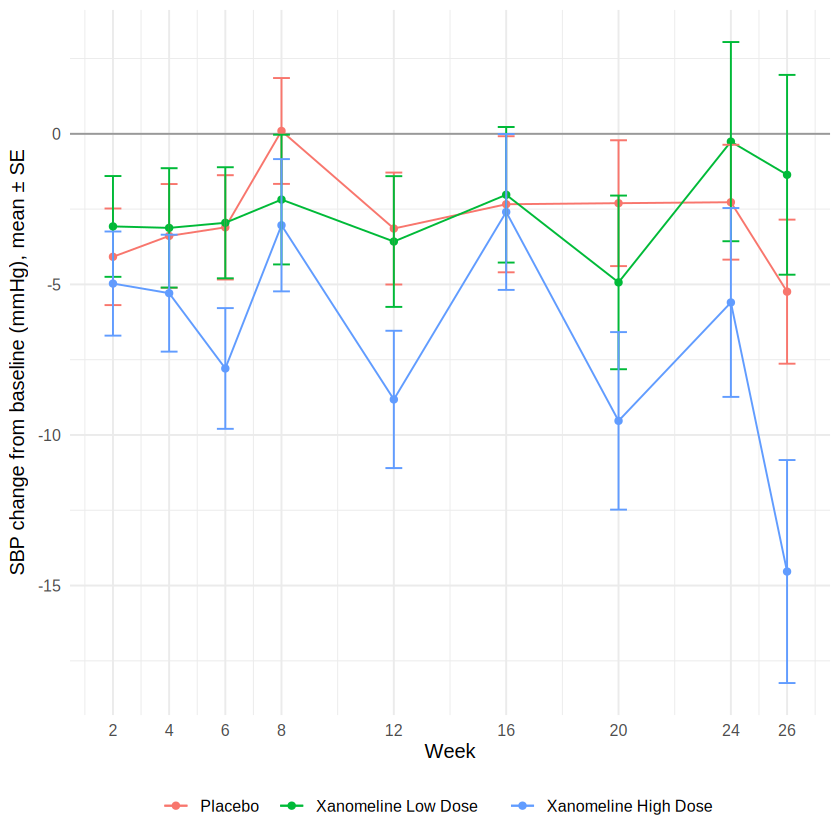

In [12]:
library(ggplot2)
advs %>%
  filter(SAFFL == "Y", PARAMCD == "SYSBP", !is.na(AVISIT), !is.na(CHG)) %>%
  mutate(TRT01A = factor(TRT01A, levels = arm_lv)) %>%
  group_by(TRT01A, AVISITN) %>%
  summarise(m = mean(CHG), se = sd(CHG) / sqrt(n())) %>%
  ggplot(aes(AVISITN, m, colour = TRT01A)) +
  geom_hline(yintercept = 0, colour = "grey60") +
  geom_line() + geom_point() +
  geom_errorbar(aes(ymin = m - se, ymax = m + se), width = 0.6) +
  scale_x_continuous(breaks = c(0, 2, 4, 6, 8, 12, 16, 20, 24, 26)) +
  labs(x = "Week", y = "SBP change from baseline (mmHg), mean ± SE", colour = NULL) +
  theme_minimal(base_size = 12) + theme(legend.position = "bottom")

## 6. 검증과 내보내기

실무에서는 같은 ADaM을 다른 사람이 독립적으로 다시 만들어 비교한다(**double programming / QC**). 여기서는 간단한 자기 점검만 한다. 제출용 파일은 SAS Transport v5(`.xpt`) 형식이며 변수명 8자, 라벨 40자 제한이 있다.

In [13]:
stopifnot(
  !any(duplicated(adsl$USUBJID)),                                     # ADSL 피험자당 1행
  all(adae$USUBJID %in% adsl$USUBJID),                                 # ADAE ⊂ ADSL
  advs %>% filter(ABLFL == "Y") %>% count(USUBJID, PARAMCD) %>% pull(n) %>% max() == 1,  # 기저치 1개
  all(is.na(advs$CHG) | abs(advs$CHG - (advs$AVAL - advs$BASE)) < 1e-8)
)
cat("자체 점검 통과\n")

long_names <- function(df) names(df)[nchar(names(df)) > 8]
cat("8자 초과 변수명 - ADSL:", long_names(adsl), " ADAE:", long_names(adae), " ADVS:", long_names(advs), "\n")

dir.create("cdisc_out", showWarnings = FALSE)
for (nm in c("adsl", "adae", "advs")) {
  df <- get(nm)
  df <- df %>% mutate(across(where(is.factor), as.character))
  write_xpt(df, file.path("cdisc_out", paste0(nm, ".xpt")), version = 5, name = toupper(nm))
}
write.csv(sdtm_dm, "cdisc_out/my_sdtm_dm.csv", row.names = FALSE)
write.csv(sdtm_ae, "cdisc_out/my_sdtm_ae.csv", row.names = FALSE)
file.info(list.files("cdisc_out", full.names = TRUE))[, "size", drop = FALSE]

자체 점검 통과
8자 초과 변수명 - ADSL:   ADAE:   ADVS:  


,size
,<dbl>
cdisc_out/adae.xpt,698960
cdisc_out/adsl.xpt,119840
cdisc_out/advs.xpt,3904560
cdisc_out/my_sdtm_ae.csv,193003
cdisc_out/my_sdtm_dm.csv,48504


## 7. 내 코호트 자료에 옮길 때

다기관 코호트(예: 처방·용량 자료)를 이 틀로 바꾸면 이렇게 대응된다.

| 코호트 자료 | SDTM | ADaM |
|---|---|---|
| 환자 기본정보(기관, 나이, 성별, 진단) | DM, MH(병력) | ADSL (기관, 연령군, 분석집단 플래그) |
| 약물 처방 기록 | CM(병용약) 또는 EX | ADCM, 또는 BDS로 일일 용량 파라미터화 |
| 척도 점수(PANSS 등) | QS | ADQS (BDS: PARAMCD=PANSS 총점, BASE, CHG) |
| 검사 수치 | LB | ADLB |
| 입원·사건 | HO, CE | ADTTE (time-to-event, CNSR) |

